In [ ]:
import seaborn as sns
import numpy as np

spot = 100
strikes = np.concatenate([np.arange(5, 105, 2.5), np.arange(105, 260, 5)])
zs = np.log(strikes / spot)

a0 = 0.10
b0 = 2.00
c0 = -0.30
d0 = 0.50
e0 = 0.215


def myvol(z: float):
    return a0 * (np.tanh(b0 * z) + c0) * (d0 + z) + e0


ivs = myvol(zs)

In [299]:
from svi import SliceSVI
import numpy as np
import seaborn as sns
import matplotlib.pyplot as mpl

tau = 1.00
r = 0.035
new = SliceSVI(tau)
new.fit(zs, ivs)

In [300]:
new.params

array([ 0.01956002,  0.04044742, -0.148342  ,  0.07334858,  0.48899571])

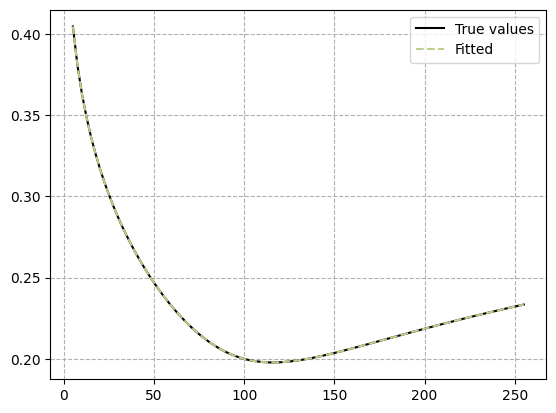

In [301]:
ivs_fit = new.bsvol(zs)
sns.lineplot(x=strikes, y=ivs, label="True values", color="k", linewidth=1.5)
sns.lineplot(
    x=strikes,
    y=ivs_fit,
    label="Fitted",
    color="#BDD089",
    linestyle="dashed",
    linewidth=1.5,
)
mpl.grid(linestyle="dashed")

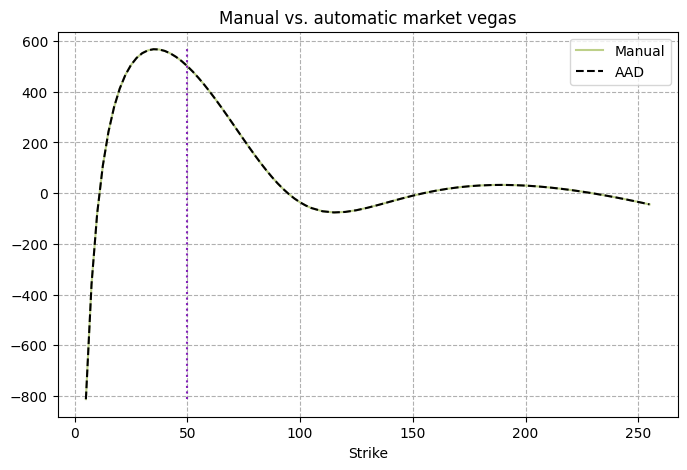

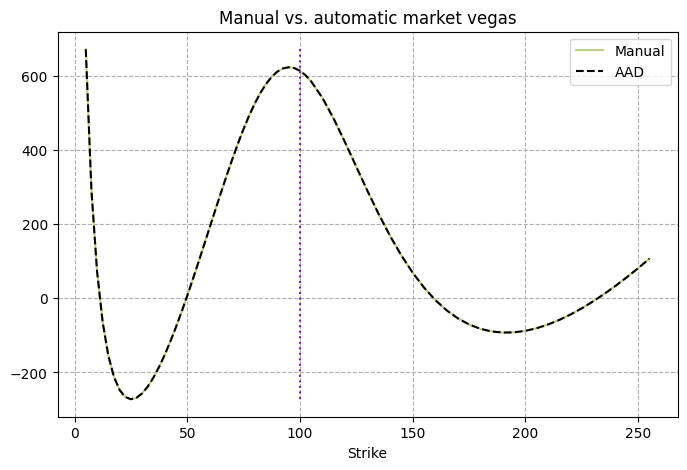

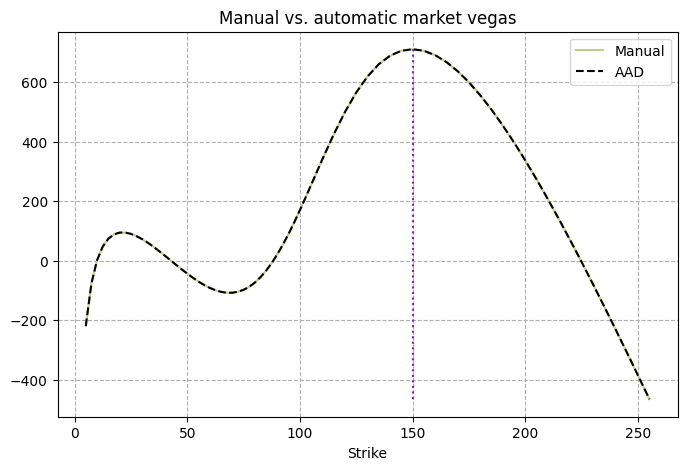

In [302]:
def manual(strike: float):
    derivs = np.zeros_like(ivs)
    bump = 1e-3
    for i in range(len(ivs)):
        tmp = ivs.copy()
        tmp[i] += bump  # one basis point
        slice = SliceSVI(tau)
        slice.fit(zs, tmp)
        slice.bscall(spot, strike, r, tau)
        pv_up = slice.pricing_results["netvalue"]
        tmp = ivs.copy()
        tmp[i] -= bump  # one basis point
        slice = SliceSVI(tau)
        slice.fit(zs, tmp)
        slice.bscall(spot, strike, r, tau)
        pv_down = slice.pricing_results["netvalue"]
        derivs[i] = (pv_up - pv_down) / (2 * bump)
    return derivs


flat_vegas = []
for k in [50, 100, 150]:
    new.bscall(spot, k, r, tau)
    vegas = new.pricing_results["vegas"]
    flat_vega = np.sum(vegas)
    flat_vegas.append(flat_vega)
    derivs = manual(k)
    mpl.figure(figsize=(8, 5))
    sns.lineplot(x=strikes, y=1e4 * derivs / flat_vega, label="Manual", color="#BDD089")
    sns.lineplot(
        x=strikes, y=1e4 * vegas / flat_vega, label="AAD", color="k", linestyle="dashed"
    )
    m0 = np.min(1e4 * vegas / flat_vega)
    M0 = np.max(1e4 * vegas / flat_vega)
    mpl.vlines(k, m0, M0, linestyle="dotted", color="#8320B8")
    mpl.legend()
    mpl.title("Manual vs. automatic market vegas")
    mpl.grid(linestyle="dashed")
    mpl.xlabel("Strike")
    mpl.show()
    mpl.close()